# DynamAuction — Library Tutorial

A complete walkthrough of the `dynamauction` library: how to create scenarios,
what the available kernel models are, how probes and delay samplers work together,
and how to interact with the Gymnasium-compatible `AuctionEnv`.

## 1. Creating Scenarios

A scenario is a complete specification of a repeated auction environment, including the primitives (auction, kernel, user model), the conversion probe, and the delay sampler.

DynamicAuc offers three ways to build a `Scenario`, ordered from fastest to most flexible. 

In [1]:
import dynamauction as dac
import numpy as np

# ── Method 1: Preset ──────────────────────────────────────────────────────────
# Pick a named scenario from the built-in registry.
print(dac.describe_scenarios())

Available Scenarios
paper-experiment-scenario           | Basic scenario used in the paper experiments
saturation-second-price-uniform     | Saturation kernel with second-price auction and uniform competition
recency-second-price-lognormal      | Recency kernel with second-price auction and lognormal competition
mixed-second-price-exponential      | Mixed kernel (immediate + delayed) with second-price and exponential competition
survival-second-price-lognormal     | Survival kernel with single conversion per display, second-price and lognormal competition

* Use get_scenario_info(scenario_id) for full technical specs.


In [2]:
# ── Method 2: Builder ─────────────────────────────────────────────────────────
# Compose primitives freely. Call order does not matter.
scenario_custom = (
    dac.ScenarioBuilder()
    .with_kernel("saturation", base_rate=0.7, saturation_scale=8.0, delay_rate=0.3)
    .with_auction("second-price")
    .with_competition("lognormal", mu=0.0, sigma=0.8)
    .with_arrival("cstpoisson", rate=1.5)
    .with_display("iid", dim=3)
    .with_exogenous("trivial")
    .with_horizon("fixed", value=30.0)
    .with_user_features("uniform", full_dim=3, observable_dim=3)
    .with_gamma("additive")
    .with_probe("poisson")        # Ogata thinning → 0..N delays
    .with_delay_sampler("multi")  # keep all sampled delays
    .with_max_history(10)
    .build()                      # Always call build() to resolve deferred configurations and get a Scenario instance.
)
print(f"Kernel  : {scenario_custom.kernel.__class__.__name__}")
print(f"Probe   : {scenario_custom.probe.__class__.__name__}")
print(f"Sampler : {scenario_custom.delay_sampler.__class__.__name__}")

Kernel  : SaturationKernel
Probe   : PoissonProbe
Sampler : MultiConversionSampler


In [3]:
# ── Method 3: Hybrid ──────────────────────────────────────────────────────────
# Start from a preset, override selected parameters via underscore-path keys. the kay "params" is ommitted for brevity, but can be used to override nested parameters.
scenario_hybrid = dac.make(
    "mixed-second-price-exponential",
    horizon_value=50.0,          # override horizon.params.value
    kernel_kappa_base_rate=0.5,  # override kernel.params.kappa_base_rate
    max_history=5,
)
print(f"Horizon    : {scenario_hybrid.horizon_generator.__class__.__name__}")
print(f"kappa rate : {scenario_hybrid.kernel.kappa_base_rate}")
print(f"max_history: {scenario_hybrid.max_history}")

Horizon    : FixedHorizon
kappa rate : 0.5
max_history: 5


## 2. Kernels, Probes & Delay Samplers

This section explains the modelling primitives that control **how a won auction generates conversions**.

### 2.1 Reward Kernels

A `RewardKernel` defines how a won display generates conversions over time.
The reward measure decomposes into an **immediate** part and a **delayed** intensity:

$$K(\cdot, ds) = \kappa(u, x, \text{ctx})\,\delta_0(ds) + \lambda(u, x, \text{ctx}, s)\,ds$$

The **context** `ctx` is updated by γ after each won auction (e.g. cumulative wins, time of last display).

| Kernel | `ctx` encodes | $\lambda(s)$ | Use case |
|--------|--------------|-------------|----------|
| `SaturationKernel` | Cumulative wins | $r_0\,e^{-\text{ctx}/\sigma}\cdot\mu e^{-\mu s}$ | Audience fatigue |
| `RecencyDisplayKernel` | Time of last display | $(1-e^{-\alpha\tau})\cdot\mu e^{-\mu s}$, $\tau=t-\text{ctx}$ | Recency of last touch |
| `CompetitorExtinctionKernel` | — | $r_0\,\mu e^{-\mu s}\cdot\mathbf{1}[\text{no competitor click}]$ | Competitor interference |
| `MixedKernel` | Delegates to base | $\kappa>0$ (immediate) + base $\lambda(s)$ (delayed) | Click-through + view-through |
| `SurvivalKernel` | Contextual scale | $f(u,x,\text{ctx})\cdot\alpha e^{-\alpha s}$, $f=\mathrm{clip}(\text{ctx}\cdot g_u^\top u\cdot g_x^\top x,\,0,1)$ | Single-purchase (Cox model) |

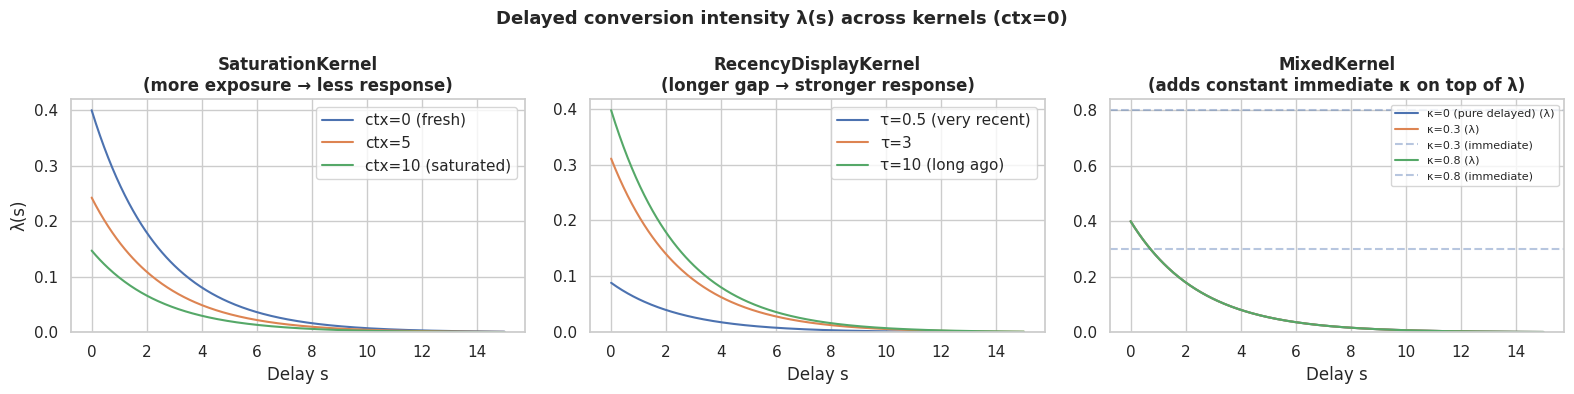

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from dynamauction.primitives import MixedKernel, SaturationKernel

sns.set_theme(style='whitegrid')

s_vals = np.linspace(0, 15, 300)
t = 0.0
u, x = np.ones(3) * 0.5, np.ones(3) * 0.5

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# SaturationKernel: effect of cumulative exposure (context)
ax = axes[0]
for ctx, lbl in [(0, 'ctx=0 (fresh)'), (5, 'ctx=5'), (10, 'ctx=10 (saturated)')]:
    k = dac.SaturationKernel(base_rate=1.0, saturation_scale=10.0, delay_rate=0.4)
    ax.plot(s_vals, [k.lambda_(u, x, ctx, 0.0, t, s) for s in s_vals], label=lbl)
ax.set_title('SaturationKernel\n(more exposure → less response)', weight='bold')
ax.set_xlabel('Delay s'); ax.set_ylabel('λ(s)'); ax.legend(); ax.set_ylim(bottom=0)

# RecencyDisplayKernel: effect of gap since last display
ax = axes[1]
for tau, lbl in [(0.5, 'τ=0.5 (very recent)'), (3, 'τ=3'), (10, 'τ=10 (long ago)')]:
    k = dac.RecencyDisplayKernel(alpha=0.5, delay_rate=0.4)
    ctx = t - tau  # ctx stores the time of last display
    ax.plot(s_vals, [k.lambda_(u, x, ctx, 0.0, t, s) for s in s_vals], label=lbl)
ax.set_title('RecencyDisplayKernel\n(longer gap → stronger response)', weight='bold')
ax.set_xlabel('Delay s'); ax.legend(); ax.set_ylim(bottom=0)

# MixedKernel: varying κ (immediate) vs λ (delayed) balance
ax = axes[2]
base = SaturationKernel(base_rate=1.0, saturation_scale=10.0, delay_rate=0.4)
for kappa_rate, lbl in [(0.0, 'κ=0 (pure delayed)'), (0.3, 'κ=0.3'), (0.8, 'κ=0.8')]:
    k = MixedKernel(base, kappa_base_rate=kappa_rate)
    ax.plot(s_vals, [k.lambda_(u, x, 0.0, 0.0, t, s) for s in s_vals], label=f'{lbl} (λ)')
    if kappa_rate > 0:
        ax.axhline(kappa_rate, linestyle='--', alpha=0.4, label=f'κ={kappa_rate} (immediate)')
ax.set_title('MixedKernel\n(adds constant immediate κ on top of λ)', weight='bold')
ax.set_xlabel('Delay s'); ax.legend(fontsize=8); ax.set_ylim(bottom=0)

plt.suptitle('Delayed conversion intensity λ(s) across kernels (ctx=0)', fontsize=13, weight='bold')
plt.tight_layout()
plt.show()

### 2.2 ConversionProbe and DelaySampler

Two components translate the kernel intensity $\lambda(s)$ into concrete delay samples for each won display.

**Step 1 — ConversionProbe:** samples candidate delay times from the kernel.

| Probe | Mechanism | Output |
|-------|-----------|--------|
| `PoissonProbe` | Ogata thinning: draw $s \leftarrow s + \mathrm{Exp}(\lambda_{\max})$, accept with prob $\lambda(s)/\lambda_{\max}$ | 0…N delays |
| `SurvivalProbe` | Draw $B\sim\mathrm{Bernoulli}(f(u,x,\text{ctx}))$; if $B=1$ sample $s\sim h(s)$ | 0 or 1 delay |

**Step 2 — DelaySampler:** decides how many delays to keep.

| Sampler | Calls | Output | Pairs with |
|---------|-------|--------|------------|
| `MultiConversionSampler` | `probe.sample_all()` | All events (0…N) | `PoissonProbe` |
| `SingleConversionSampler` | `probe.sample_one()` | At most 1 event | `SurvivalProbe` |

---

**How delays $s$ are sampled**

*PoissonProbe — Ogata thinning:*

$$s_0 = 0, \qquad s_{k+1} = s_k + \mathrm{Exp}(\lambda_{\max}), \qquad \text{accept } s_{k+1} \text{ with prob } \frac{\lambda(s_{k+1})}{\lambda_{\max}}$$

Repeat until $s_k > T - t$. The accepted times $\{s_{k}\}$ form a non-homogeneous Poisson process with intensity $\lambda(s)$. Each accepted $s_k$ becomes one conversion delay.

*SurvivalProbe — two-step factorisation:*

The `SurvivalKernel` factorises as $\lambda(s) = f(u, x, \text{ctx}) \cdot h(s)$ where $h(s) = \alpha e^{-\alpha s}$.
This gives an exact two-step sampler:

$$B \sim \mathrm{Bernoulli}\!\left(\int_0^{T-t} \lambda(s)\,ds\right) = \mathrm{Bernoulli}\!\left(f(u,x,\text{ctx})\cdot(1 - e^{-\alpha(T-t)})\right)$$

$$\text{if } B = 1:\quad s \sim h(s) = \alpha e^{-\alpha s}, \text{ i.e. } s \sim \mathrm{Exp}(\alpha), \text{ truncated to } [0,\, T-t]$$

This produces at most one conversion per display, consistent with a single-purchase survival model.

---

**Step-by-step: what happens when the agent wins an auction**

1. The environment calls `probe.sample_all()` (or `sample_one()`) with $(u, x, \text{ctx}, t, T)$.
2. The probe queries $\lambda_{\max} = \lambda\_\text{upper\_bound}(u, x, \text{ctx}, t)$ and simulates the point process over $[0,\, T-t]$.
3. Each candidate delay $s_k$ is accepted with probability $\lambda(s_k)/\lambda_{\max}$.
4. The sampler filters: `Multi` keeps all accepted delays, `Single` keeps at most one.
5. The filtered delays are stored as **pending conversions**. At each future step $t' \geq t + s_k$, the environment delivers the reward to the agent.

The cell below makes this explicit by calling the probe directly:

In [ ]:
import numpy as np
import dynamauction as dac
from dynamauction.primitives import SaturationKernel
from dynamauction.primitives.conversion_probe import PoissonProbe
from dynamauction.primitives.delay_sampler import MultiConversionSampler

rng = np.random.default_rng(0)
u   = np.array([0.5, 0.5, 0.5])   # user features
x   = np.array([0.3, 0.7, 0.5])   # display features
ctx = 2.0                          # context (e.g. 2 prior wins → mild saturation)
t   = 5.0                          # current auction time
T   = 20.0                         # campaign horizon

kernel  = SaturationKernel(base_rate=1.0, saturation_scale=10.0, delay_rate=0.4)
probe   = PoissonProbe(kernel)
sampler = MultiConversionSampler(probe)

delays = sampler.sample(u, x, ctx, y=0.0, t=t, horizon=T, rng=rng)
print(f"ctx = {ctx}  →  {len(delays)} conversion(s) sampled at delays: {[round(d, 3) for d in delays]}")
print(f"Absolute conversion times: {[round(t + d, 3) for d in delays]}")

# Compare: fresh user (ctx=0) vs saturated (ctx=10)
for c in [0.0, 5.0, 10.0]:
    d = sampler.sample(u, x, c, y=0.0, t=t, horizon=T, rng=np.random.default_rng(42))
    print(f"  ctx={c:4.0f}  →  {len(d)} conversion(s)")

### 2.3 Built-in Preset Scenarios

Each preset bundles a kernel, probe, and sampler tuned to a specific modelling paradigm:

| Preset | Kernel | Probe | Sampler | Canonical use case |
|---|---|---|---|---|
| `saturation-second-price-uniform` | `SaturationKernel` | Poisson | Multi | Display retargeting: audience fatigue, many delayed clicks per impression |
| `recency-second-price-lognormal` | `RecencyDisplayKernel` | Poisson | Multi | Email/push: freshness of last touch drives response rate |
| `mixed-second-price-exponential` | `MixedKernel` (κ>0, saturation base) | Poisson | Multi | Rich-media/video: immediate click-through plus delayed view-through conversions |
| `survival-second-price-lognormal` | `SurvivalKernel` | Survival | Single | Single-purchase e-commerce: Cox-style model, user buys at most once |

In [5]:
# Build every preset and inspect expected reward at campaign start
rng_ref = np.random.default_rng(42)
u_ref, x_ref = np.ones(3) * 0.5, np.ones(3) * 0.5

rows = []
for pid in dac.list_scenarios():
    sc = dac.make(pid)
    ctx0 = sc.gamma.initiate_context()
    horizon = min(sc.horizon_generator.sample(rng_ref), 30.0)
    er = sc.kernel.expected_reward(u_ref, x_ref, ctx0, lambda _: 0.0, t=0.0, horizon=horizon)
    rows.append({
        "preset": pid,
        "kernel": sc.kernel.__class__.__name__,
        "probe": sc.probe.__class__.__name__,
        "sampler": sc.delay_sampler.__class__.__name__,
        "E[reward | ctx=0]": round(er, 4),
    })

import pandas as pd
pd.set_option('display.max_colwidth', 35)
pd.DataFrame(rows).set_index('preset')

,kernel,probe,sampler,E[reward | ctx=0]
preset,,,,
paper-experiment-scenario,MixedKernel,PoissonProbe,MultiConversionSampler,0.5000
saturation-second-price-uniform,SaturationKernel,PoissonProbe,MultiConversionSampler,0.5000
recency-second-price-lognormal,RecencyDisplayKernel,PoissonProbe,MultiConversionSampler,1.0000
mixed-second-price-exponential,MixedKernel,PoissonProbe,MultiConversionSampler,0.6323
survival-second-price-lognormal,SurvivalKernel,SurvivalProbe,SingleConversionSampler,0.0000


## 3. Environment Interaction

The cells below demonstrate the step-by-step Gymnasium loop, visualise auction timings
and delayed reward delivery, and show how the kernel state (`ctx`, `expected_reward`) evolves
over a campaign.

In [6]:
import dynamauction as dac
from dynamauction.baseline.policies import FiPlaPolicy
import gymnasium as gym
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style='whitegrid')

### 3.1 Episode loop
We use the `mixed-second-price-exponential` preset, which generates both immediate and delayed conversions. We run a single episode with `FiPlaPolicy` and record everything the agent observes.

In [7]:
scenario = dac.make('mixed-second-price-exponential', horizon_value=50.0, kernel_base_kernel_delay_rate=0.5)
env = gym.make('DynamAuction-v0', scenario=scenario)
policy = FiPlaPolicy()

obs, info = env.reset(seed=123)
done = False
history = []
cum_reward = 0.0

while not done:
    # Agent decides on a bid
    bid = policy.bid(obs)
    pre_step_obs = obs
    
    # Agent takes action
    obs, net_reward, done, truncated, step_info = env.step(bid)
    
    cum_reward += net_reward
    
    # Record state for visualization
    history.append({
        'step': pre_step_obs['step'],
        'time': pre_step_obs['t'].item(),
        'context': pre_step_obs['ctx'].item(),
        'expected_reward': pre_step_obs['expected_reward'].item(),
        'delayed_reward_observed': pre_step_obs['cumulative_reward_since_last_step'].item(),
        'conversion_times_since_last': [t.item() for t in pre_step_obs['conversion_times_since_last_step']],
        'bid': bid,
        'won': step_info['auction']['won'],
        'immediate_reward': net_reward,
        'cumulative_reward': cum_reward
    })

df = pd.DataFrame(history)
df.head(40)

,step,time,context,expected_reward,delayed_reward_observed,conversion_times_since_last,bid,won,immediate_reward,cumulative_reward
0,0,8.295199,0.0,0.700000,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.700000,False,0.000000,0.000000
1,1,9.216899,0.0,0.700000,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.700000,True,0.909359,0.909359
2,2,10.688148,1.0,0.652419,1.0,"[9.369508743286133, 0.0, 0.0, 0...",0.652419,True,0.979592,1.888951
3,3,11.577782,2.0,0.609365,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.609365,False,0.000000,1.888951
4,4,11.595409,2.0,0.609365,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.609365,True,-0.186762,1.702189
5,5,12.248230,3.0,0.570409,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.570409,True,-0.347230,1.354958
6,6,13.828720,4.0,0.535160,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.535160,True,-0.376465,0.978493
7,7,24.889448,5.0,0.503264,1.0,"[15.004340171813965, 0.0, 0.0, ...",0.503264,False,1.000000,1.978493
8,8,25.648523,5.0,0.503264,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.503264,False,0.000000,1.978493
9,9,25.908253,5.0,0.503264,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.503264,True,-0.259732,1.718761


### 3.2 Auction timeline
Let's map out when the agent bid, whether it won or lost, and when it received notifications of delayed conversions.

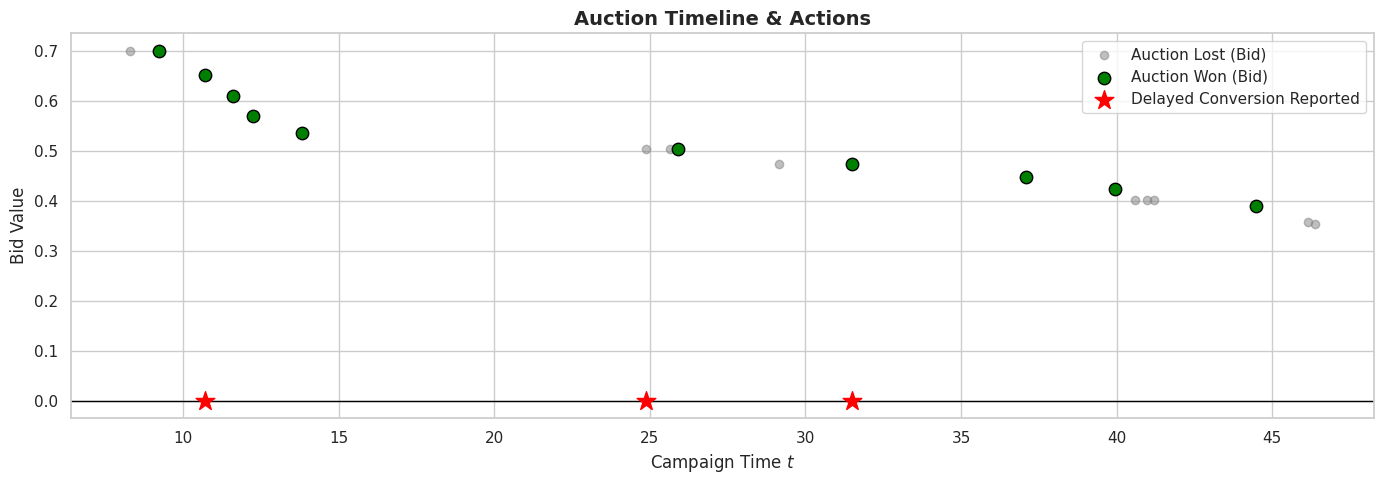

In [8]:
def plot_auction_timeline(df):
    plt.figure(figsize=(14, 5))
    
    lost = df[~df['won']]
    won = df[df['won']]
    
    plt.scatter(lost['time'], lost['bid'], color='gray', alpha=0.5, label='Auction Lost (Bid)')
    plt.scatter(won['time'], won['bid'], color='green', s=80, label='Auction Won (Bid)', edgecolor='black')
    
    # Plot when delayed conversions were reported to the agent
    reported_times = []
    for _, row in df.iterrows():
        if row['delayed_reward_observed'] > 0:
            # Add one marker per conversion reported
            reported_times.extend([row['time']] * int(row['delayed_reward_observed']))
            
    if reported_times:
        plt.scatter(reported_times, [0] * len(reported_times), color='red', marker='*', s=200, label='Delayed Conversion Reported', zorder=5)
        
    plt.title('Auction Timeline & Actions', fontsize=14, weight='bold')
    plt.xlabel('Campaign Time $t$')
    plt.ylabel('Bid Value')
    plt.axhline(0, color='black', linewidth=1)
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

plot_auction_timeline(df)

### 3.3 Step-by-step reward
Because of the delayed environment, the agent receives two types of feedback: immediate feedback for the current action, and delayed feedback from past actions that matured.

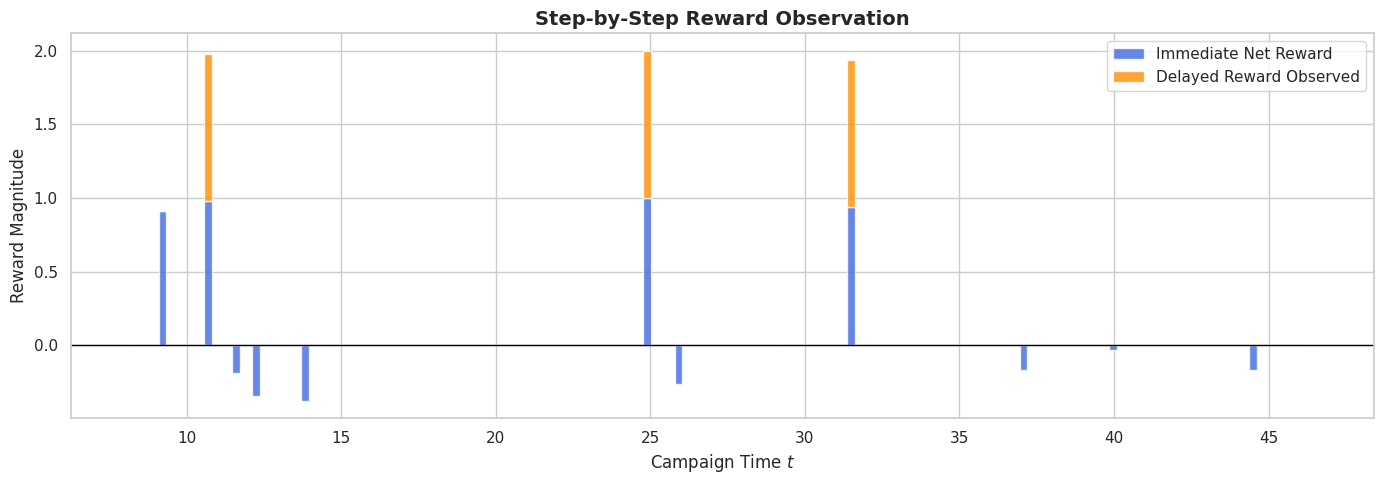

In [9]:
def plot_reward_dynamics(df):
    plt.figure(figsize=(14, 5))
    
    plt.bar(df['time'], df['immediate_reward'], width=0.25, label='Immediate Net Reward', color='royalblue', alpha=0.8)
    
    # Stack delayed rewards on top of immediate positive rewards for visibility
    plt.bar(df['time'], df['delayed_reward_observed'], width=0.25, bottom=np.maximum(0, df['immediate_reward']), label='Delayed Reward Observed', color='darkorange', alpha=0.8)
    
    plt.title('Step-by-Step Reward Observation', fontsize=14, weight='bold')
    plt.xlabel('Campaign Time $t$')
    plt.ylabel('Reward Magnitude')
    plt.axhline(0, color='black', linewidth=1)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_reward_dynamics(df)

### 3.4 Cumulative reward and kernel state
Finally, we can look at the overarching trend of the episode. As the agent wins more auctions, the cumulative reward goes up, but the `expected_reward` (value of future displays) goes down due to saturation.

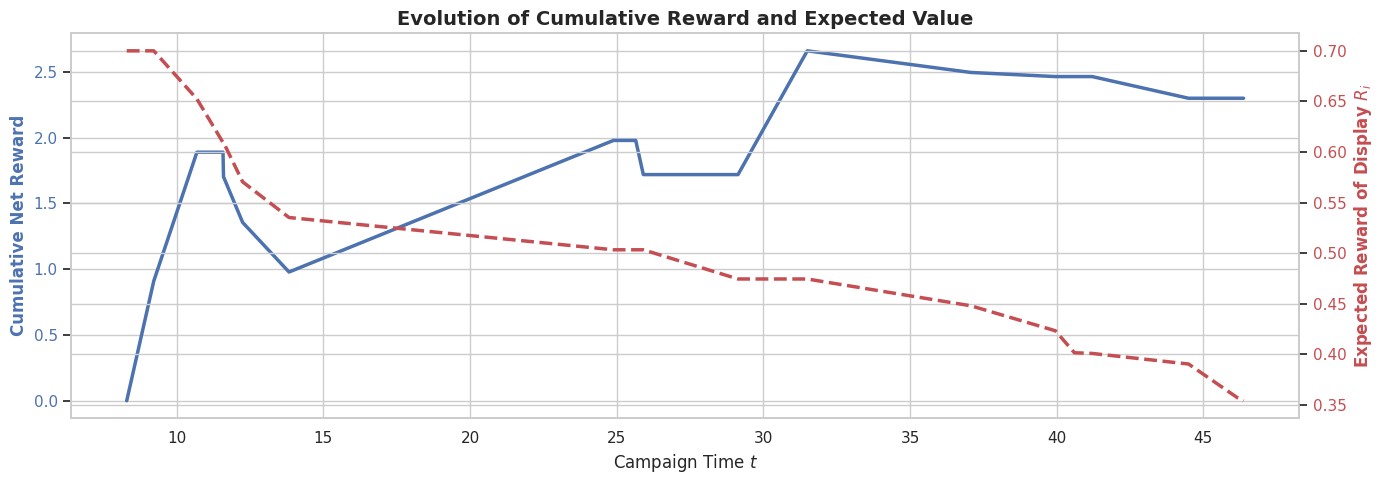

In [10]:
def plot_cumulative_metrics(df):
    fig, ax1 = plt.subplots(figsize=(14, 5))
    
    ax1.plot(df['time'], df['cumulative_reward'], 'b-', linewidth=2.5, label='Cumulative Net Reward')
    ax1.set_xlabel('Campaign Time $t$')
    ax1.set_ylabel('Cumulative Net Reward', color='b', weight='bold')
    ax1.tick_params(axis='y', labelcolor='b')
    
    ax2 = ax1.twinx()
    ax2.plot(df['time'], df['expected_reward'], 'r--', linewidth=2.5, label='Expected Reward (State)')
    ax2.set_ylabel('Expected Reward of Display $R_i$', color='r', weight='bold')
    ax2.tick_params(axis='y', labelcolor='r')
    
    plt.title('Evolution of Cumulative Reward and Expected Value', fontsize=14, weight='bold')
    fig.tight_layout()
    plt.show()

plot_cumulative_metrics(df)

## 4. Gym Wrappers

`DynamAuction-v0` follows the standard [Gymnasium](https://gymnasium.farama.org/) API,
making it directly compatible with any library that consumes Gymnasium environments:
[Stable Baselines3](https://stable-baselines3.readthedocs.io/), [TorchRL](https://pytorch.org/rl/),
[CleanRL](https://docs.cleanrl.dev/), [RLlib](https://docs.ray.io/en/latest/rllib/), and others.

Three wrappers ship with `dynamauction` to bridge the raw environment with RL training pipelines:

| Wrapper | Type | Purpose |
|---------|------|---------|
| `FlatAuctionObsWrapper` | `ObservationWrapper` | Flattens the Dict observation to a 1-D `float32` vector — required by MLP policies |
| `BidScaleWrapper` | `ActionWrapper` | Rescales the action from `[0, 1]` to `[0, max_bid]` for stable exploration |
| `MaskExpectedRewardWrapper` | `ObservationWrapper` | Drops `expected_reward` from the observation — use for fair RL vs FiPla comparison |
| `SB3PolicyWrapper` | `BiddingPolicy` adapter | Wraps a trained SB3 model so it can be evaluated in the raw-Dict env |

### Recommended training stack (Stable Baselines3)

```python
import gymnasium as gym
import dynamauction as dac
from dynamauction import FlatAuctionObsWrapper, BidScaleWrapper, MaskExpectedRewardWrapper
from stable_baselines3 import PPO
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize

scenario = dac.make('survival-second-price-exponential', horizon_eta=50)

def make_env():
    env = gym.make('DynamAuction-v0', scenario=scenario)
    env = MaskExpectedRewardWrapper(env)  # hide oracle signal from RL agent
    env = FlatAuctionObsWrapper(env)      # Dict obs → 1-D vector
    env = BidScaleWrapper(env, max_bid=5.0)
    env = Monitor(env)
    return env

vec_env = DummyVecEnv([make_env] * 4)
vec_env = VecNormalize(vec_env, norm_obs=True, norm_reward=True)

model = PPO('MlpPolicy', vec_env, verbose=1)
model.learn(total_timesteps=500_000)
```

### Evaluating a trained SB3 model in the raw Dict env

After training, use `SB3PolicyWrapper` to plug the model into the `Simulator`
or any code that expects a `BiddingPolicy`:

```python
import pickle
from dynamauction.wrappers import SB3PolicyWrapper
from dynamauction.simulator import Simulator

# Load VecNormalize statistics saved at training time
with open('benchmark/models/ppo/obs_rms.pkl', 'rb') as f:
    obs_rms = pickle.load(f)

raw_env = gym.make('DynamAuction-v0', scenario=scenario)
ppo_policy = SB3PolicyWrapper(
    model, raw_env.observation_space,
    obs_rms=obs_rms,
    exclude_keys=['expected_reward'],  # must match training wrappers
)

# Now ppo_policy behaves like any BiddingPolicy
sim = Simulator(scenario, {'PPO': ppo_policy, 'FiPla': dac.FiPlaPolicy()},
                campaign_cfg={'n_runs': 30, 'seed': 0})
_, _, _, summary = sim.run()
print(summary.groupby('policy')[['win_rate', 'n_conversions']].mean())
```

> **Why `MaskExpectedRewardWrapper`?** `expected_reward` is the oracle value
> $\kappa + \int\lambda\,ds$ that `FiPlaPolicy` bids directly.
> Exposing it to an RL agent gives it privileged information a real advertiser would not have.
> Remove it whenever the RL vs FiPla comparison should be fair.